In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

df = pd.read_csv("../data/Adequate_Sleep_data.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())


Dataset loaded successfully!
Number of rows and columns: (100, 8)


,Timestamp,1.What is your age? (Number<0),"2.On average, how many hours do you sleep per night? (0<number<24)",3.What time do you usually go to bed? (Time: HH:MM),"4.How much time do you spend using screens (phone, laptop, TV) in a typical day?","5.How often do you consume caffeine (coffee, tea, energy drinks)?",6.How many minutes do you exercise on a typical day? (0<number<1440),7.How would you describe your daily workload or stress?
0,5/31/2026 23:32:48,18.0,4.6,1:04,4–6 hours,Rarely,46.0,Sometimes
1,4/2/2026 15:53:39,18.0,8.1,NaN,2–4 hours,Rarely,NaN,Never
2,4/18/2026 21:54:50,25.0,7.0,0:35,More than 8 hours,3 or more times a day,11.0,Always
3,6/28/2026 19:19:52,31.0,8.6,21:33,More than 8 hours,1–2 times a day,NaN,Always
4,3/18/2026 10:16:27,28.0,7.9,0:07,More than 8 hours,3 or more times a day,34.0,Rarely


In [3]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)


Column names:
['Timestamp', '1.What is your age? (Number<0)', '2.On average, how many hours do you sleep per night? (0<number<24)', '3.What time do you usually go to bed? (Time: HH:MM)', '4.How much time do you spend using screens (phone, laptop, TV) in a typical day?', '5.How often do you consume caffeine (coffee, tea, energy drinks)?', '6.How many minutes do you exercise on a typical day? (0<number<1440)', '7.How would you describe your daily workload or stress?']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column                                                                            Non-Null Count  Dtype  
---  ------                                                                            --------------  -----  
 0   Timestamp                                                                         100 non-null    str    
 1   1.What is your age? (Number<0)                                               

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Timestamp,100,100,5/31/2026 23:32:48,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1.What is your age? (Number<0),94.0,NaN,NaN,NaN,27.670213,9.797288,18.0,20.0,27.0,32.0,91.0
"2.On average, how many hours do you sleep per night? (0<number<24)",96.0,NaN,NaN,NaN,7.617708,2.479304,1.6,6.375,7.25,8.025,16.1
3.What time do you usually go to bed? (Time: HH:MM),93,79,0:35,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"4.How much time do you spend using screens (phone, laptop, TV) in a typical day?",98,5,More than 8 hours,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"5.How often do you consume caffeine (coffee, tea, energy drinks)?",95,4,1–2 times a day,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6.How many minutes do you exercise on a typical day? (0<number<1440),93.0,NaN,NaN,NaN,57.021505,71.222856,0.0,24.0,42.0,61.0,490.0
7.How would you describe your daily workload or stress?,96,5,Sometimes,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:

# Keep the original dataset unchanged
df_clean = df.drop(columns=["Timestamp"]).copy()

print("Timestamp column removed.")
print("Original dataset shape:", df.shape)
print("Dataset shape after removing Timestamp:", df_clean.shape)

display(df_clean.head())

# Keep the original dataset unchanged
df_clean = df.drop(columns=["Timestamp"]).copy()

print("Timestamp column removed.")
print("Original dataset shape:", df.shape)
print("Dataset shape after removing Timestamp:", df_clean.shape)

display(df_clean.head())


Timestamp column removed.
Original dataset shape: (100, 8)
Dataset shape after removing Timestamp: (100, 7)


,1.What is your age? (Number<0),"2.On average, how many hours do you sleep per night? (0<number<24)",3.What time do you usually go to bed? (Time: HH:MM),"4.How much time do you spend using screens (phone, laptop, TV) in a typical day?","5.How often do you consume caffeine (coffee, tea, energy drinks)?",6.How many minutes do you exercise on a typical day? (0<number<1440),7.How would you describe your daily workload or stress?
0,18.0,4.6,1:04,4–6 hours,Rarely,46.0,Sometimes
1,18.0,8.1,NaN,2–4 hours,Rarely,NaN,Never
2,25.0,7.0,0:35,More than 8 hours,3 or more times a day,11.0,Always
3,31.0,8.6,21:33,More than 8 hours,1–2 times a day,NaN,Always
4,28.0,7.9,0:07,More than 8 hours,3 or more times a day,34.0,Rarely


Timestamp column removed.
Original dataset shape: (100, 8)
Dataset shape after removing Timestamp: (100, 7)


,1.What is your age? (Number<0),"2.On average, how many hours do you sleep per night? (0<number<24)",3.What time do you usually go to bed? (Time: HH:MM),"4.How much time do you spend using screens (phone, laptop, TV) in a typical day?","5.How often do you consume caffeine (coffee, tea, energy drinks)?",6.How many minutes do you exercise on a typical day? (0<number<1440),7.How would you describe your daily workload or stress?
0,18.0,4.6,1:04,4–6 hours,Rarely,46.0,Sometimes
1,18.0,8.1,NaN,2–4 hours,Rarely,NaN,Never
2,25.0,7.0,0:35,More than 8 hours,3 or more times a day,11.0,Always
3,31.0,8.6,21:33,More than 8 hours,1–2 times a day,NaN,Always
4,28.0,7.9,0:07,More than 8 hours,3 or more times a day,34.0,Rarely


In [5]:

df_clean.columns = [
    "age",
    "sleep_hours",
    "bedtime",
    "screen_time",
    "caffeine",
    "exercise_minutes",
    "workload_stress"
]

print("Updated column names:")
print(df_clean.columns.tolist())


Updated column names:
['age', 'sleep_hours', 'bedtime', 'screen_time', 'caffeine', 'exercise_minutes', 'workload_stress']


In [6]:

# Count missing values in each column
missing_count = df_clean.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (missing_count / len(df_clean)) * 100

# Combine the results into a table
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage.round(2)
})

display(missing_summary)


,Missing Values,Missing Percentage
age,6,6.0
sleep_hours,4,4.0
bedtime,7,7.0
screen_time,2,2.0
caffeine,5,5.0
exercise_minutes,7,7.0
workload_stress,4,4.0


In [7]:

# Create a separate dataset for modeling
df_model = df_clean.copy()

# Remove rows where sleep duration is missing
df_model = df_model.dropna(subset=["sleep_hours"]).copy()

# Create the target classification label
df_model["sleep_category"] = np.where(
    df_model["sleep_hours"].between(7, 9, inclusive="both"),
    "Adequate",
    "Inadequate"
)

print("Dataset shape after removing missing sleep duration:",
      df_model.shape)

print("\nSleep category counts:")
print(df_model["sleep_category"].value_counts())

print("\nSleep category percentages:")
print(
    (df_model["sleep_category"].value_counts(normalize=True) * 100)
    .round(2)
)

display(df_model[["sleep_hours", "sleep_category"]].head(10))


Dataset shape after removing missing sleep duration: (96, 8)

Sleep category counts:
sleep_category
Adequate      52
Inadequate    44
Name: count, dtype: int64

Sleep category percentages:
sleep_category
Adequate      54.17
Inadequate    45.83
Name: proportion, dtype: float64


,sleep_hours,sleep_category
0,4.6,Inadequate
1,8.1,Adequate
2,7.0,Adequate
3,8.6,Adequate
4,7.9,Adequate
5,8.3,Adequate
6,7.4,Adequate
7,15.3,Inadequate
8,6.1,Inadequate
9,8.8,Adequate


In [8]:

print("Missing values after creating the target:")
print(df_model.isnull().sum())

print("\nData types:")
print(df_model.dtypes)

print("\nUnique values in categorical columns:")
for column in ["bedtime", "screen_time", "caffeine", "workload_stress"]:
    print(f"\n{column}:")
    print(df_model[column].value_counts(dropna=False))


Missing values after creating the target:
age                 6
sleep_hours         0
bedtime             7
screen_time         2
caffeine            5
exercise_minutes    7
workload_stress     4
sleep_category      0
dtype: int64

Data types:
age                 float64
sleep_hours         float64
bedtime                 str
screen_time             str
caffeine                str
exercise_minutes    float64
workload_stress         str
sleep_category          str
dtype: object

Unique values in categorical columns:

bedtime:
bedtime
NaN      7
0:35     4
0:25     3
0:29     2
22:01    2
        ..
1:10     1
1:17     1
0:56     1
23:33    1
0:14     1
Name: count, Length: 77, dtype: int64

screen_time:
screen_time
More than 8 hours    32
4–6 hours            20
6–8 hours            18
2–4 hours            17
Less than 2 hours     7
NaN                   2
Name: count, dtype: int64

caffeine:
caffeine
1–2 times a day          41
Rarely                   21
3 or more times a day    18
Ne

In [9]:

# Make a separate copy for data preparation
df_prepared = df_model.copy()

# Fill missing numerical values using the median
numeric_columns = ["age", "exercise_minutes"]

for column in numeric_columns:
    df_prepared[column] = df_prepared[column].fillna(
        df_prepared[column].median()
    )

# Fill missing categorical values using the most frequent response
categorical_columns = [
    "bedtime",
    "screen_time",
    "caffeine",
    "workload_stress"
]

for column in categorical_columns:
    df_prepared[column] = df_prepared[column].fillna(
        df_prepared[column].mode()[0]
    )

print("Missing values after imputation:")
print(df_prepared.isnull().sum())

print("\nPrepared dataset shape:", df_prepared.shape)


Missing values after imputation:
age                 0
sleep_hours         0
bedtime             0
screen_time         0
caffeine            0
exercise_minutes    0
workload_stress     0
sleep_category      0
dtype: int64

Prepared dataset shape: (96, 8)


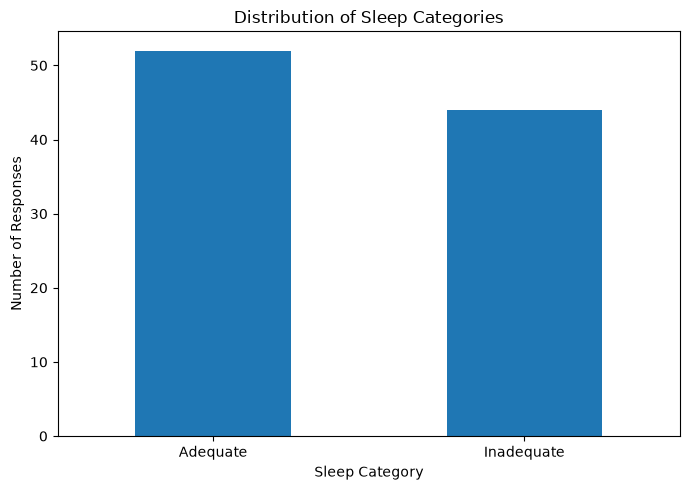

In [10]:

# Count responses in each sleep category
category_counts = df_prepared["sleep_category"].value_counts()

plt.figure(figsize=(7, 5))
category_counts.plot(kind="bar")

plt.title("Distribution of Sleep Categories")
plt.xlabel("Sleep Category")
plt.ylabel("Number of Responses")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


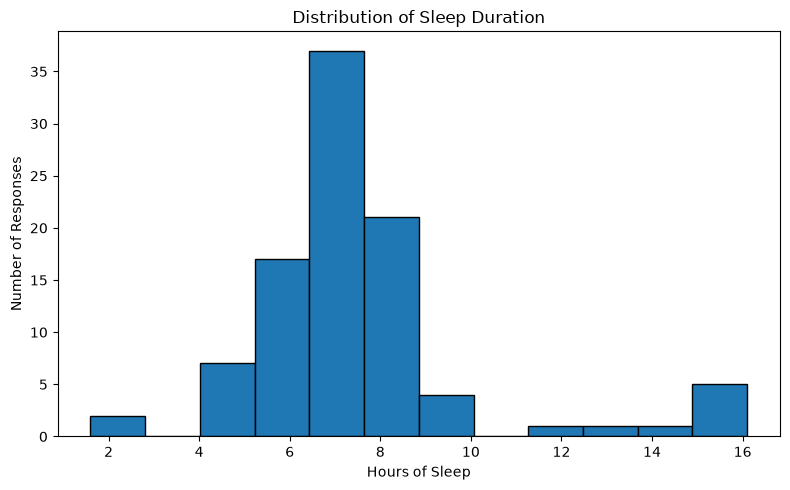

In [11]:

plt.figure(figsize=(8, 5))

plt.hist(df_prepared["sleep_hours"], bins=12, edgecolor="black")

plt.title("Distribution of Sleep Duration")
plt.xlabel("Hours of Sleep")
plt.ylabel("Number of Responses")
plt.tight_layout()
plt.show()


In [12]:

# Inspect unusually low and high sleep durations
unusual_sleep = df_prepared[
    (df_prepared["sleep_hours"] < 4) |
    (df_prepared["sleep_hours"] > 12)
]

print("Number of unusual sleep-duration responses:",
      len(unusual_sleep))

display(
    unusual_sleep[["age", "sleep_hours", "sleep_category"]]
    .sort_values("sleep_hours")
)


Number of unusual sleep-duration responses: 10


,age,sleep_hours,sleep_category
93,26.0,1.6,Inadequate
55,31.0,2.6,Inadequate
98,28.0,12.2,Inadequate
67,36.0,13.4,Inadequate
81,18.0,14.0,Inadequate
83,26.0,14.9,Inadequate
65,27.0,15.0,Inadequate
7,34.0,15.3,Inadequate
61,32.0,15.5,Inadequate
56,24.0,16.1,Inadequate


In [13]:

# Select the input features
feature_columns = [
    "age",
    "bedtime",
    "screen_time",
    "caffeine",
    "exercise_minutes",
    "workload_stress"
]

X = df_prepared[feature_columns].copy()
y = df_prepared["sleep_category"].copy()

print("Input features:", X.columns.tolist())
print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())


Input features: ['age', 'bedtime', 'screen_time', 'caffeine', 'exercise_minutes', 'workload_stress']

Input shape: (96, 6)
Target shape: (96,)

Target distribution:
sleep_category
Adequate      52
Inadequate    44
Name: count, dtype: int64


In [14]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


Training samples: 76
Testing samples: 20

Training class distribution:
sleep_category
Adequate      41
Inadequate    35
Name: count, dtype: int64

Testing class distribution:
sleep_category
Adequate      11
Inadequate     9
Name: count, dtype: int64


In [15]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

# Separate numerical and categorical features
numeric_features = ["age", "exercise_minutes"]

categorical_features = [
    "bedtime",
    "screen_time",
    "caffeine",
    "workload_stress"
]

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Create the complete model pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


Test Accuracy: 50.00%

Classification Report:
              precision    recall  f1-score   support

    Adequate       0.55      0.55      0.55        11
  Inadequate       0.44      0.44      0.44         9

    accuracy                           0.50        20
   macro avg       0.49      0.49      0.49        20
weighted avg       0.50      0.50      0.50        20



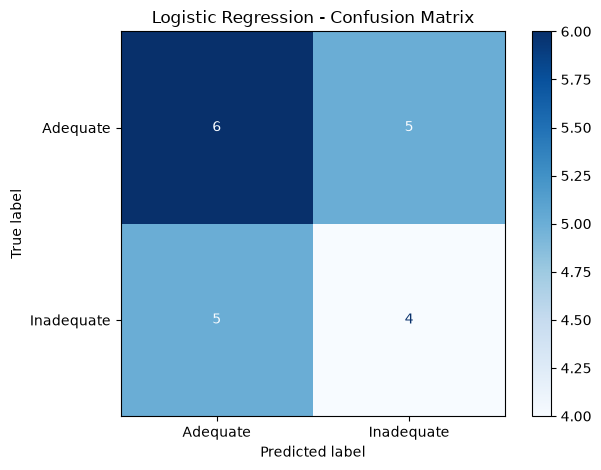

In [16]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predict the test set
y_pred = logistic_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy:.2%}")

# Print detailed metrics
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Adequate", "Inadequate"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


Decision Tree Test Accuracy: 50.00%

Classification Report:
              precision    recall  f1-score   support

    Adequate       0.55      0.55      0.55        11
  Inadequate       0.44      0.44      0.44         9

    accuracy                           0.50        20
   macro avg       0.49      0.49      0.49        20
weighted avg       0.50      0.50      0.50        20



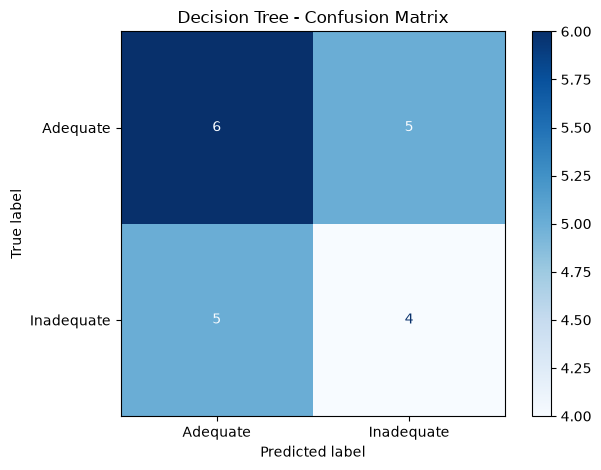

In [17]:

import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

# Identify categorical and numerical columns
categorical_features = [
    "bedtime",
    "screen_time",
    "caffeine",
    "workload_stress"
]

numerical_features = [
    "age",
    "exercise_minutes"
]

# Convert categorical values into numerical indicators
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numerical", "passthrough", numerical_features)
    ]
)

# Create a pipeline that prepares data and trains the model
decision_tree = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ))
])

# Train and predict
decision_tree.fit(X_train, y_train)
y_pred_tree = decision_tree.predict(X_test)

# Evaluate
print("Decision Tree Test Accuracy:",
      f"{accuracy_score(y_test, y_pred_tree) * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_tree, zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tree,
    labels=["Adequate", "Inadequate"],
    cmap="Blues"
)

plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()


Random Forest Test Accuracy: 60.00%

Classification Report:
              precision    recall  f1-score   support

    Adequate       0.67      0.55      0.60        11
  Inadequate       0.55      0.67      0.60         9

    accuracy                           0.60        20
   macro avg       0.61      0.61      0.60        20
weighted avg       0.61      0.60      0.60        20



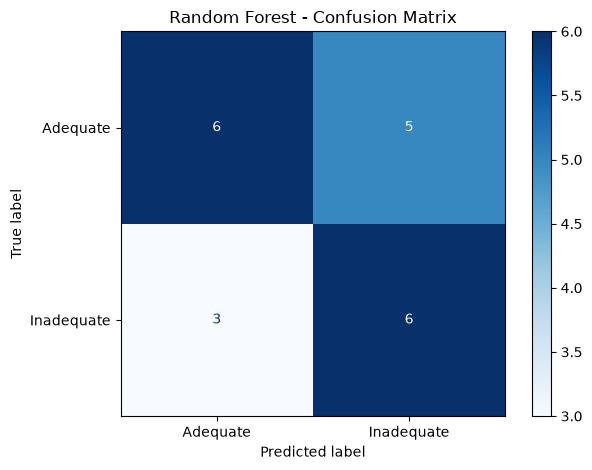

In [18]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create the Random Forest model
random_forest = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=4,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train the model
random_forest.fit(X_train, y_train)

# Predict on the test set
y_pred_rf = random_forest.predict(X_test)

# Evaluate the model
print(
    "Random Forest Test Accuracy:",
    f"{accuracy_score(y_test, y_pred_rf) * 100:.2f}%"
)

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_rf, zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    labels=["Adequate", "Inadequate"],
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()


Model Performance Comparison:


,Model,Accuracy (%)
0,Logistic Regression,50.0
1,Decision Tree,50.0
2,Random Forest,60.0


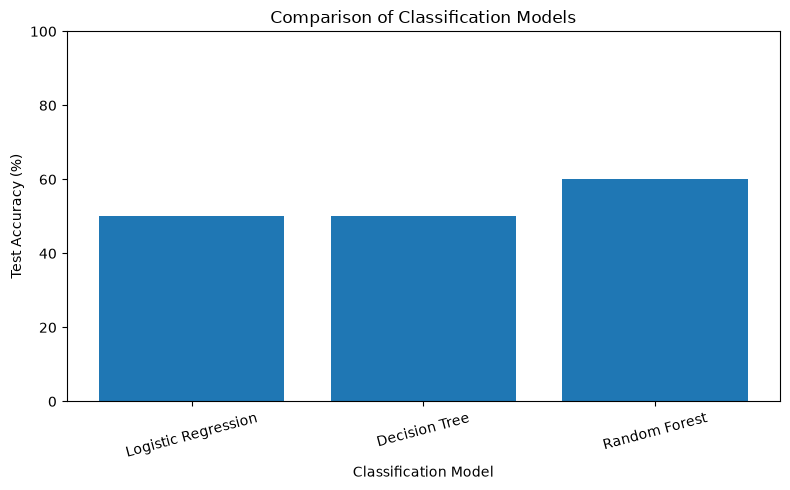

Model Performance Comparison:


,Model,Accuracy (%)
0,Logistic Regression,50.0
1,Decision Tree,50.0
2,Random Forest,60.0


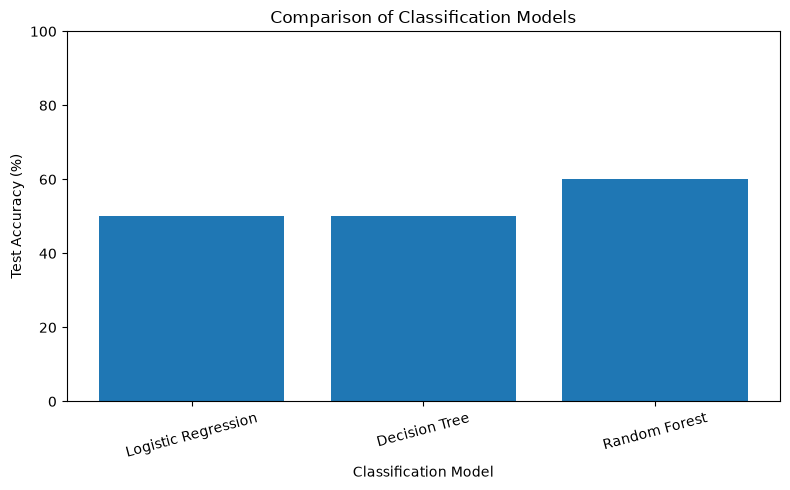

In [19]:
# Compare the accuracy of all three classification models

from sklearn.metrics import accuracy_score
import pandas as pd
import matplotlib.pyplot as plt

model_results = {
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy (%)": [
        accuracy_score(y_test, y_pred) * 100,
        accuracy_score(y_test, y_pred_tree) * 100,
        accuracy_score(y_test, y_pred_rf) * 100
    ]
}

results_df = pd.DataFrame(model_results)

print("Model Performance Comparison:")
display(results_df.round(2))

# Visualize model accuracy
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["Accuracy (%)"])
plt.title("Comparison of Classification Models")
plt.xlabel("Classification Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()# Compare the accuracy of all three classification models

from sklearn.metrics import accuracy_score
import pandas as pd
import matplotlib.pyplot as plt

model_results = {
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy (%)": [
        accuracy_score(y_test, y_pred) * 100,
        accuracy_score(y_test, y_pred_tree) * 100,
        accuracy_score(y_test, y_pred_rf) * 100
    ]
}

results_df = pd.DataFrame(model_results)

print("Model Performance Comparison:")
display(results_df.round(2))

# Visualize model accuracy
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["Accuracy (%)"])
plt.title("Comparison of Classification Models")
plt.xlabel("Classification Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Random Forest Feature Importance:


,Feature,Importance
77,numerical__exercise_minutes,0.113966
76,numerical__age,0.082788
68,categorical__caffeine_3 or more times a day,0.051871
75,categorical__workload_stress_Sometimes,0.046158
72,categorical__workload_stress_Never,0.045640
...,...,...
16,categorical__bedtime_0:56,0.002149
39,categorical__bedtime_22:08,0.001975
54,categorical__bedtime_23:26,0.001597
53,categorical__bedtime_23:15,0.000474


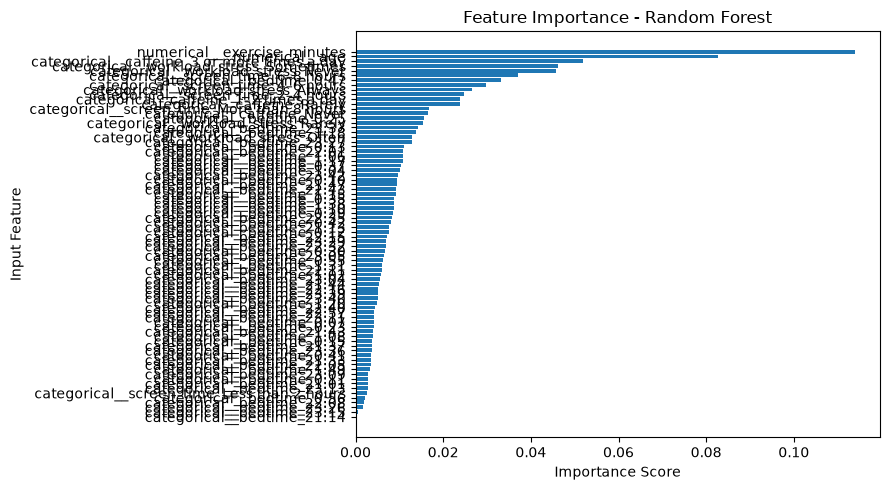

In [20]:

# Identify the Random Forest classifier inside the pipeline
rf_model = random_forest.named_steps["classifier"]

# Get the feature names after preprocessing
preprocessor = random_forest.named_steps["preprocessor"]
feature_names = preprocessor.get_feature_names_out()

# Create a table of feature importance
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Random Forest Feature Importance:")
display(feature_importance)

# Plot feature importance
plt.figure(figsize=(9, 5))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)
plt.xlabel("Importance Score")
plt.ylabel("Input Feature")
plt.title("Feature Importance - Random Forest")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [21]:
print("Pipeline steps:")
print(random_forest.named_steps)

print("\nOriginal input columns:")
print(X.columns.tolist())

print("\nRandom Forest model:")
print(random_forest.named_steps[
    list(random_forest.named_steps.keys())[-1]
])

Pipeline steps:
{'preprocessor': ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['bedtime', 'screen_time', 'caffeine',
                                  'workload_stress']),
                                ('numerical', 'passthrough',
                                 ['age', 'exercise_minutes'])]), 'classifier': RandomForestClassifier(class_weight='balanced', max_depth=4, random_state=42)}

Original input columns:
['age', 'bedtime', 'screen_time', 'caffeine', 'exercise_minutes', 'workload_stress']

Random Forest model:
RandomForestClassifier(class_weight='balanced', max_depth=4, random_state=42)


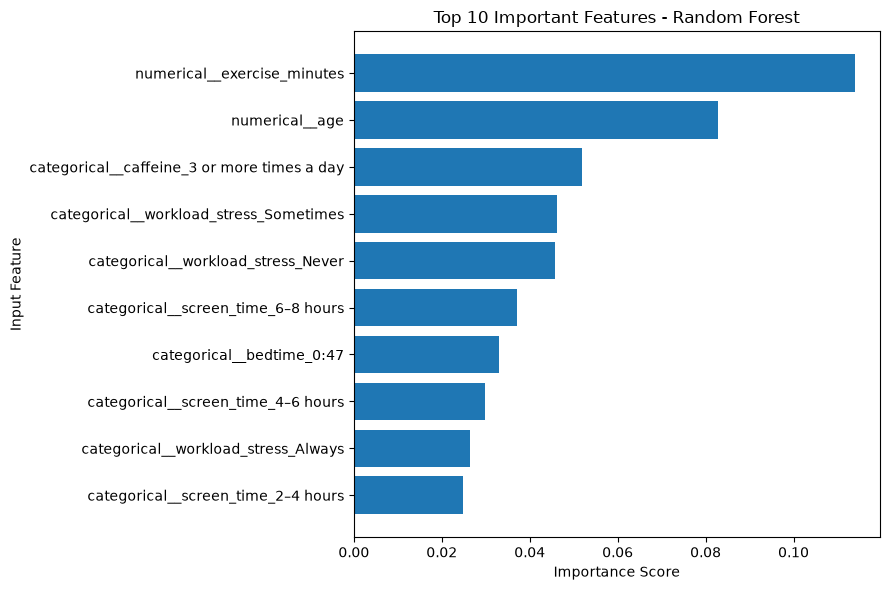

In [22]:
# Display only the 10 most important features
top_features = feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Input Feature")
plt.title("Top 10 Important Features - Random Forest")
plt.tight_layout()
plt.show()

In [23]:
# Test the Random Forest model with a new example

new_person = pd.DataFrame([{
    "age": 22,
    "bedtime": "23:00",
    "screen_time": "4–6 hours",
    "caffeine": "1–2 times a day",
    "exercise_minutes": 30,
    "workload_stress": "Sometimes"
}])

# Predict the sleep category
prediction = random_forest.predict(new_person)

print("Predicted Sleep Category:", prediction[0])

Predicted Sleep Category: Inadequate


In [24]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Compare the three trained models
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, predictions) * 100, 2),
        "Precision (Macro)": round(
            precision_score(y_test, predictions, average="macro", zero_division=0), 3
        ),
        "Recall (Macro)": round(
            recall_score(y_test, predictions, average="macro", zero_division=0), 3
        ),
        "F1-Score (Macro)": round(
            f1_score(y_test, predictions, average="macro", zero_division=0), 3
        )
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy (%),Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Logistic Regression,50.0,0.495,0.495,0.495
1,Decision Tree,50.0,0.495,0.495,0.495
2,Random Forest,60.0,0.606,0.606,0.600


In [25]:
# Check dataset size and data quality

print("Total usable responses:", len(df_prepared))

print("\nSleep category distribution:")
print(df_prepared["sleep_category"].value_counts())

print("\nMissing values in each column:")
print(df_prepared.isnull().sum())

print("\nPercentage of each sleep category:")
print(
    (df_prepared["sleep_category"].value_counts(normalize=True) * 100)
    .round(2)
)

Total usable responses: 96

Sleep category distribution:
sleep_category
Adequate      52
Inadequate    44
Name: count, dtype: int64

Missing values in each column:
age                 0
sleep_hours         0
bedtime             0
screen_time         0
caffeine            0
exercise_minutes    0
workload_stress     0
sleep_category      0
dtype: int64

Percentage of each sleep category:
sleep_category
Adequate      54.17
Inadequate    45.83
Name: proportion, dtype: float64


In [26]:
print("Input feature columns:")
print(X.columns.tolist())

print("\nDoes sleep_hours appear in the input features?")
print("sleep_hours" in X.columns)

Input feature columns:
['age', 'bedtime', 'screen_time', 'caffeine', 'exercise_minutes', 'workload_stress']

Does sleep_hours appear in the input features?
False


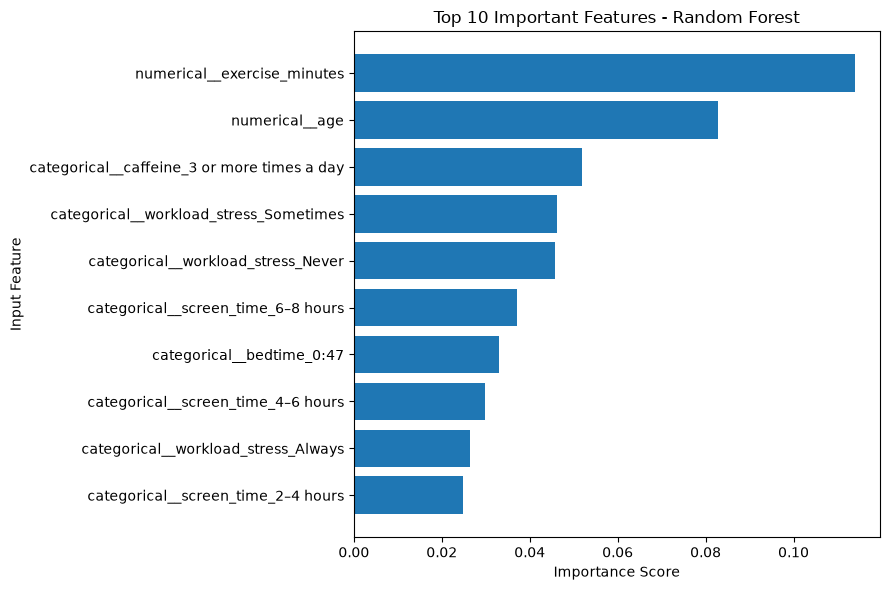

In [27]:
# Show only the 10 most important features
top_10 = feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))
plt.barh(top_10["Feature"], top_10["Importance"])
plt.xlabel("Importance Score")
plt.ylabel("Input Feature")
plt.title("Top 10 Important Features - Random Forest")
plt.tight_layout()
plt.show()